# Notebook 05: Comprehensive Model Comparison
## Graduation Thesis: CNN-BiLSTM-Attention Model for Electricity Load Forecasting in a Microgrid

Comprehensive comparison of five models:
1. LSTM
2. GRU
3. BiLSTM
4. CNN-LSTM
5. **CNN-BiLSTM-Attention (Proposed Model)**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, json, joblib, warnings
import tensorflow as tf
from helpers import inverse_transform_target, calculate_metrics

warnings.filterwarnings('ignore')

PROJECT_DIR = os.getcwd()
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')

# Load test data
data = np.load(os.path.join(DATA_DIR, 'processed_data.npz'))
X_test, y_test = data['X_test'], data['y_test']

with open(os.path.join(DATA_DIR, 'config.json')) as f:
    config = json.load(f)

scaler = joblib.load(os.path.join(DATA_DIR, 'scaler.pkl'))
TARGET_IDX = config['TARGET_IDX']
n_features = config['n_features']

y_true_real = inverse_transform_target(y_test, scaler, TARGET_IDX, n_features)
print(f'Test samples: {len(y_test)}')

Test samples: 2559


## 1. Load All Models and Generate Predictions

In [2]:
# Import attention layer for loading proposed model
import sys
sys.path.insert(0, PROJECT_DIR)

# Load predictions from saved files
baseline_pred = np.load(os.path.join(RESULTS_DIR, 'baseline_predictions.npz'))
advanced_pred = np.load(os.path.join(RESULTS_DIR, 'advanced_predictions.npz'))
proposed_pred = np.load(os.path.join(RESULTS_DIR, 'proposed_predictions.npz'))

predictions = {
    'LSTM': baseline_pred['y_pred_lstm'],
    'GRU': baseline_pred['y_pred_gru'],
    'BiLSTM': advanced_pred['y_pred_bilstm'],
    'CNN-LSTM': advanced_pred['y_pred_cnn_lstm'],
    'CNN-BiLSTM-Attention': proposed_pred['y_pred'],
}

# Calculate metrics for all models
all_metrics = {}
for name, y_pred in predictions.items():
    all_metrics[name] = calculate_metrics(y_true_real, y_pred)

results_df = pd.DataFrame(all_metrics).T
results_df = results_df.sort_values('MAPE')
results_df.to_csv(os.path.join(RESULTS_DIR, 'final_comparison.csv'))
print(results_df)

                             MAE        RMSE      MAPE        R2
LSTM                   34.878381   57.592798  0.363839  0.988001
CNN-BiLSTM-Attention   34.851402   56.521157  0.371421  0.988443
BiLSTM                 43.911054   65.035345  0.636348  0.984699
CNN-LSTM               90.199281  117.615571  1.566908  0.949956
GRU                   132.426656  160.468353  3.429379  0.906847


## 2. Visualization

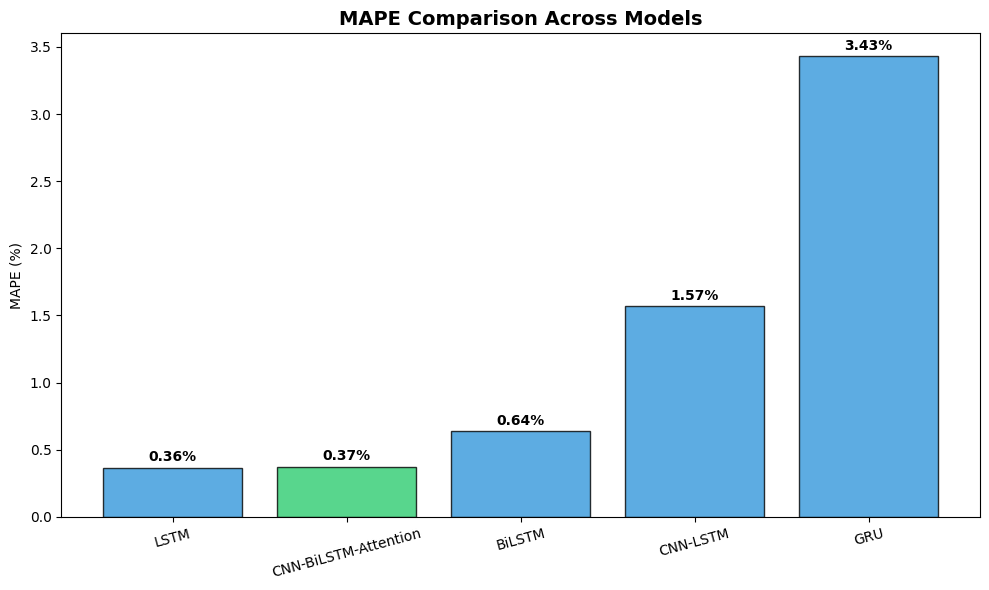

In [3]:
# 2.1 MAPE bar chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2ecc71' if name == 'CNN-BiLSTM-Attention' else '#3498db' for name in results_df.index]
bars = ax.bar(results_df.index, results_df['MAPE'], color=colors, edgecolor='black', alpha=0.8)
ax.set_title('MAPE Comparison Across Models', fontsize=14, fontweight='bold')
ax.set_ylabel('MAPE (%)')
for bar, val in zip(bars, results_df['MAPE']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{val:.2f}%', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'comparison_mape_bar.png'), dpi=150)
plt.show()

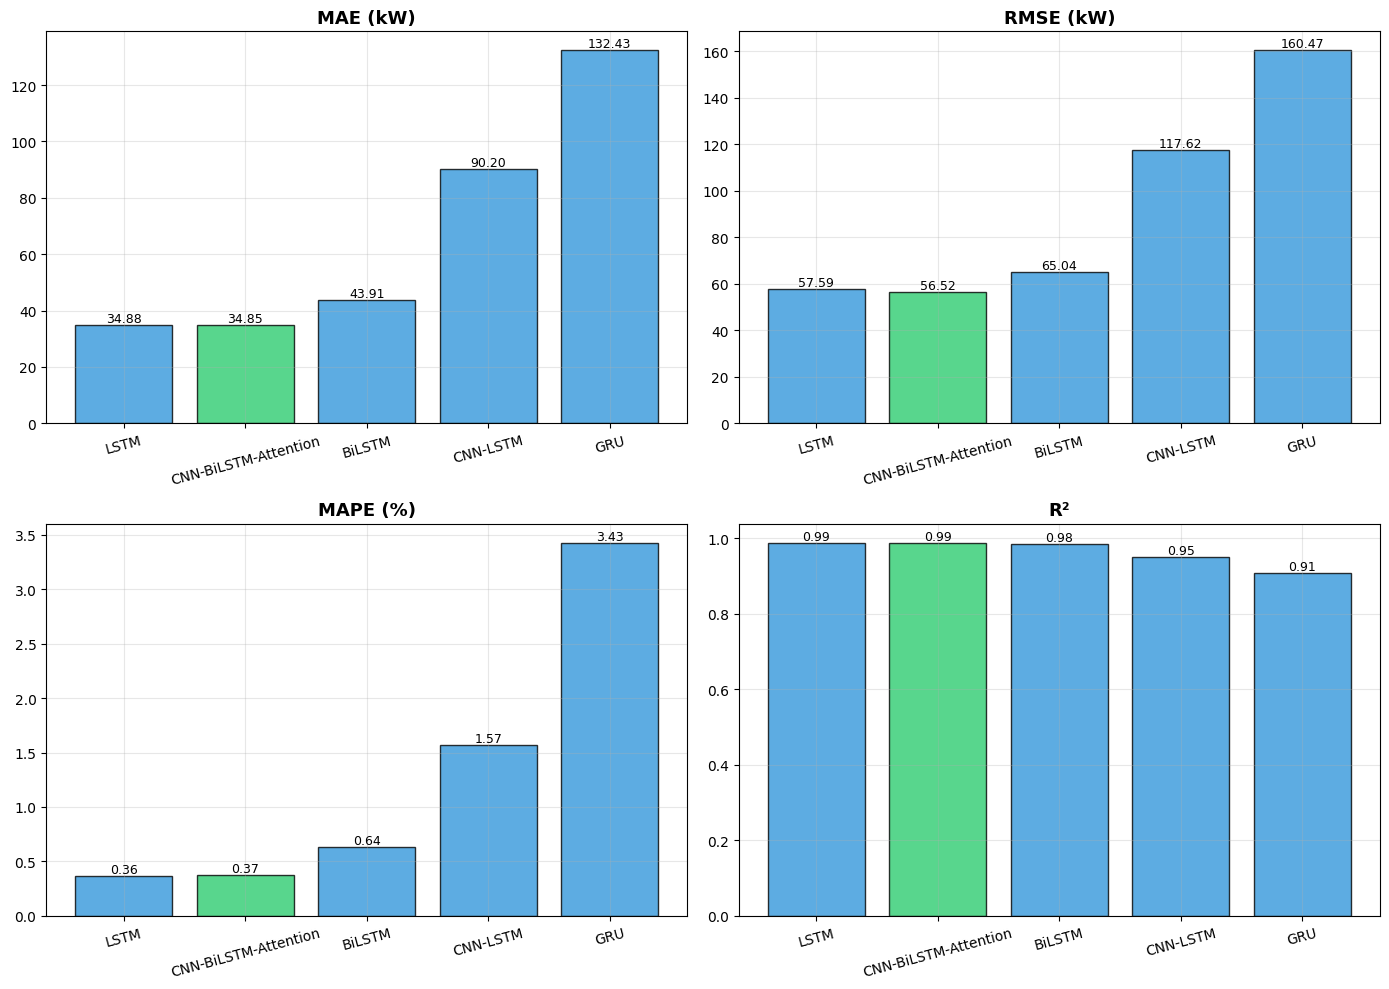

In [4]:
# 2.2 All metrics comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics_list = ['MAE', 'RMSE', 'MAPE', 'R2']
titles = ['MAE (kW)', 'RMSE (kW)', 'MAPE (%)', 'R²']

for ax, metric, title in zip(axes.flat, metrics_list, titles):
    vals = results_df[metric]
    colors = ['#2ecc71' if n == 'CNN-BiLSTM-Attention' else '#3498db' for n in results_df.index]
    bars = ax.bar(results_df.index, vals, color=colors, edgecolor='black', alpha=0.8)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(True, alpha=0.3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{v:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'comparison_all_metrics.png'), dpi=150)
plt.show()

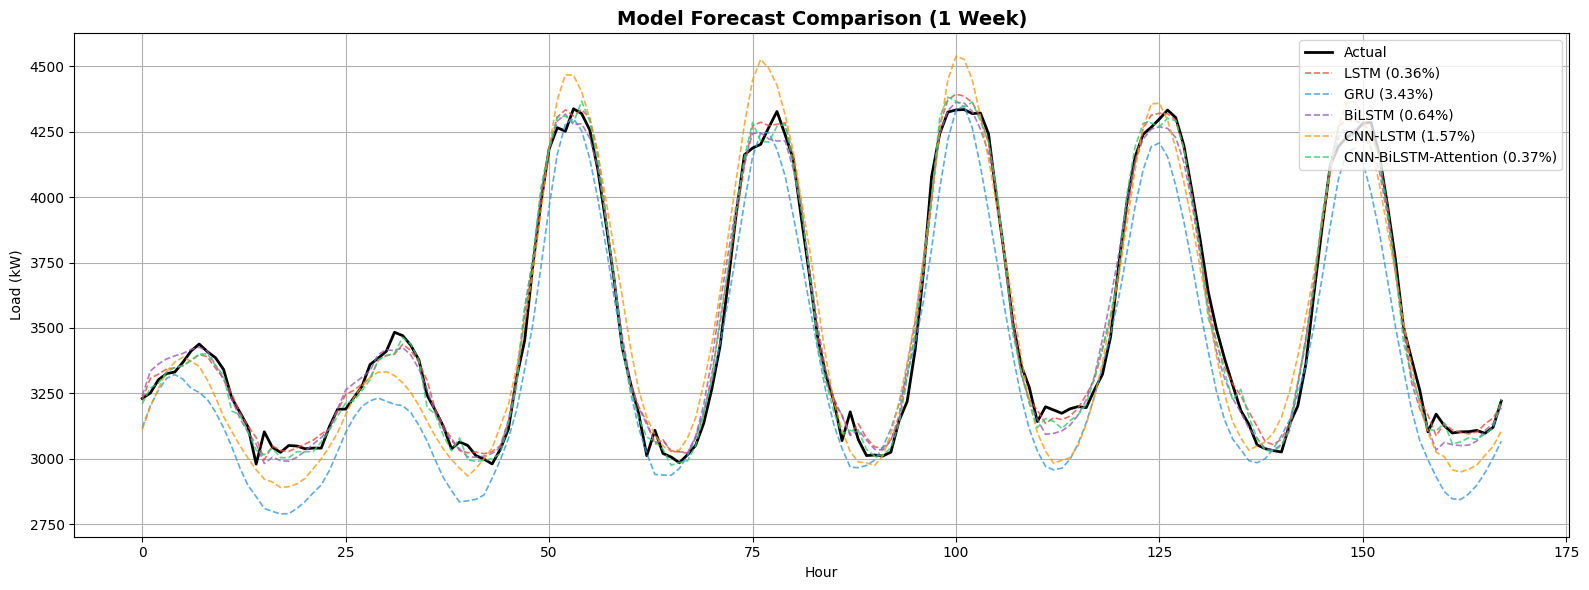

In [5]:
# 2.3 Predictions comparison (1 week)
fig, ax = plt.subplots(figsize=(16, 6))
n = 168
ax.plot(range(n), y_true_real[:n], 'k-', label='Actual', linewidth=2)

colors_line = ['#e74c3c', '#3498db', '#9b59b6', '#f39c12', '#2ecc71']
for (name, y_pred), color in zip(predictions.items(), colors_line):
    mape = all_metrics[name]['MAPE']
    ax.plot(range(n), y_pred[:n], '--', label=f'{name} ({mape:.2f}%)',
            color=color, alpha=0.8, linewidth=1.2)

ax.set_title('Model Forecast Comparison (1 Week)', fontsize=14, fontweight='bold')
ax.set_xlabel('Hour')
ax.set_ylabel('Load (kW)')
ax.legend(loc='upper right')
ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'comparison_all_predictions.png'), dpi=150)
plt.show()

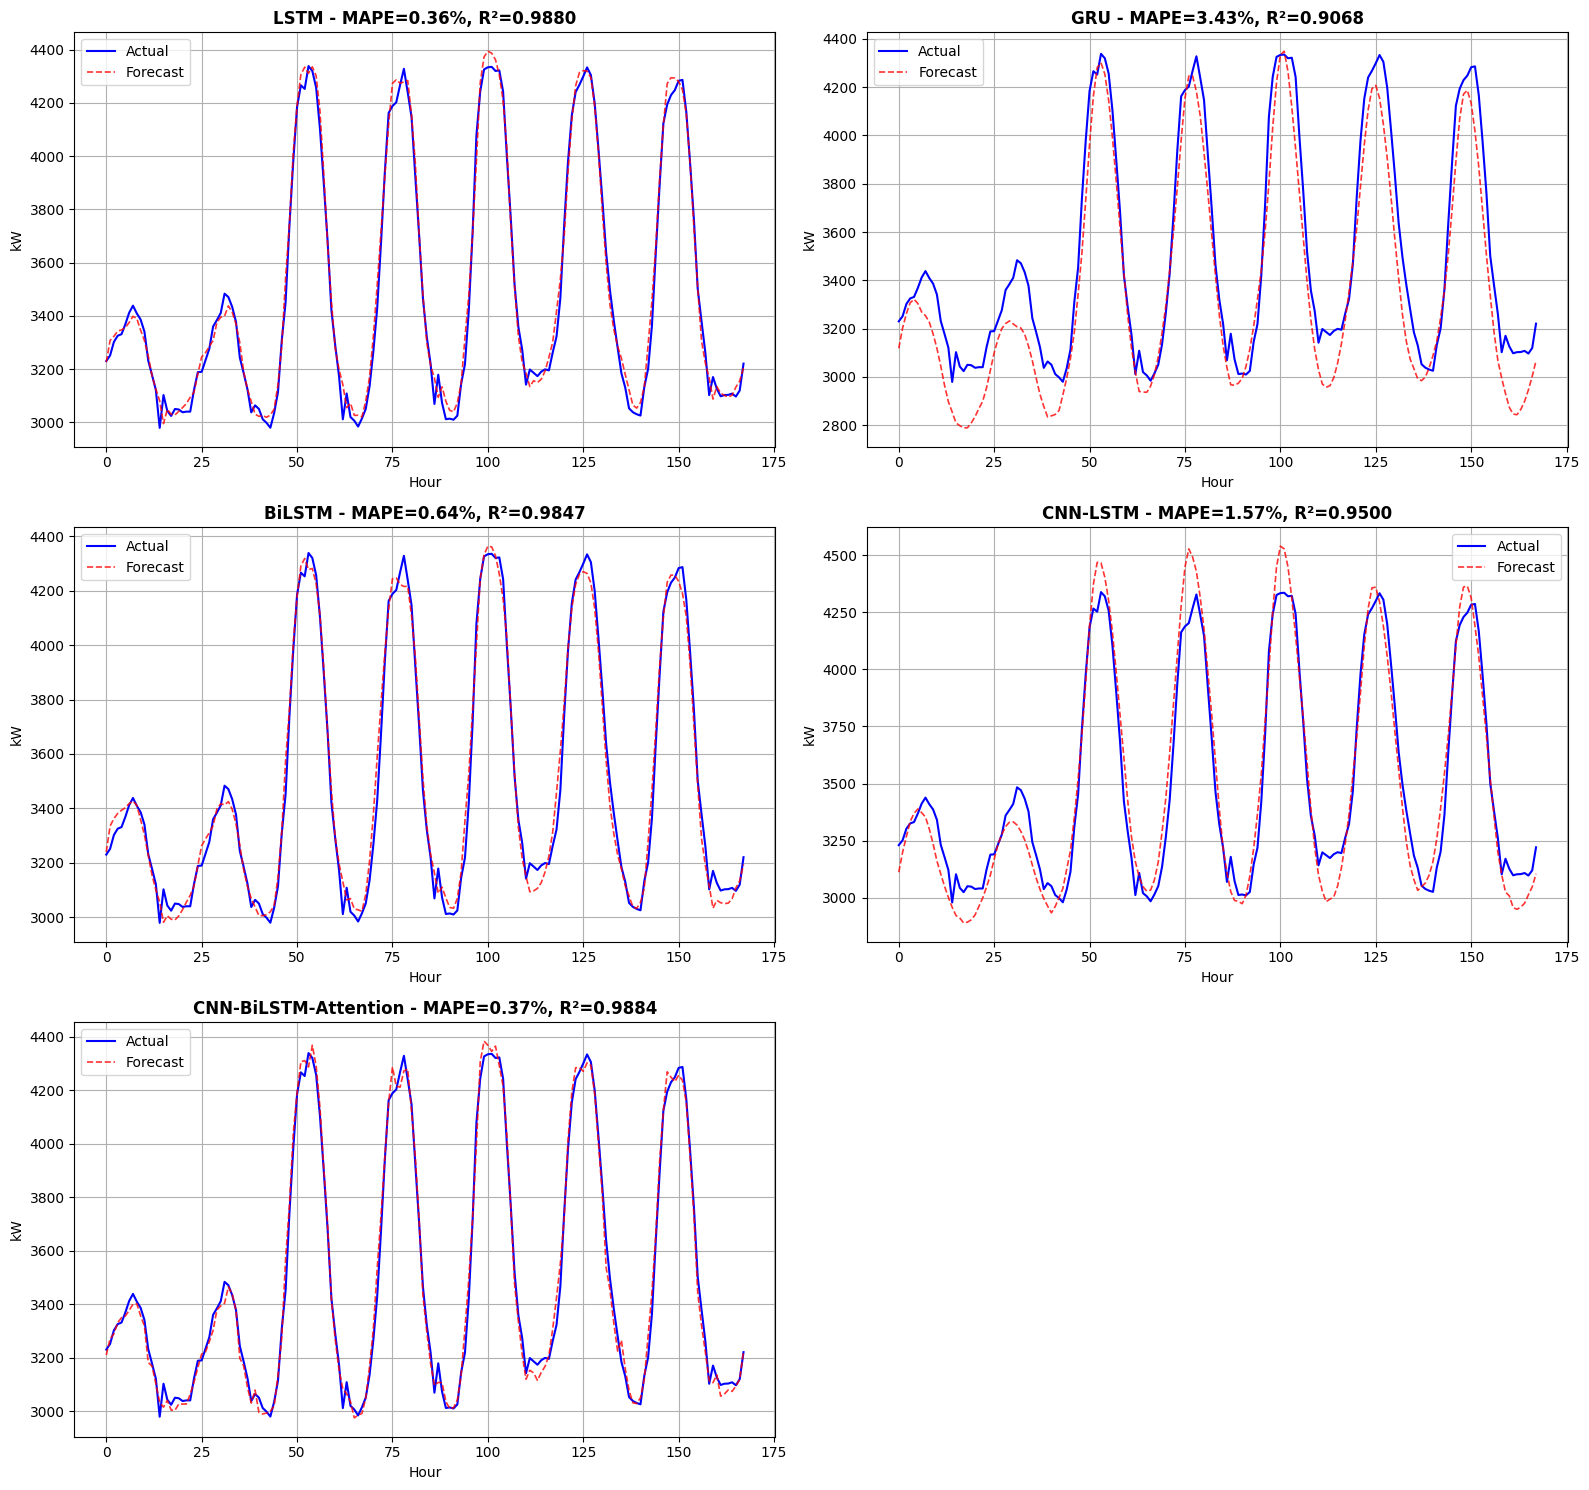

In [6]:
# 2.4 Individual comparison plots
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

n = 168
for i, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[i]
    ax.plot(range(n), y_true_real[:n], 'b-', label='Actual', linewidth=1.5)
    ax.plot(range(n), y_pred[:n], 'r--', label='Forecast', linewidth=1.2, alpha=0.8)
    mape = all_metrics[name]['MAPE']
    r2 = all_metrics[name]['R2']
    ax.set_title(f'{name} - MAPE={mape:.2f}%, R²={r2:.4f}', fontweight='bold')
    ax.set_xlabel('Hour')
    ax.set_ylabel('kW')
    ax.legend()
    ax.grid(True)

axes[5].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'comparison_individual.png'), dpi=150)
plt.show()

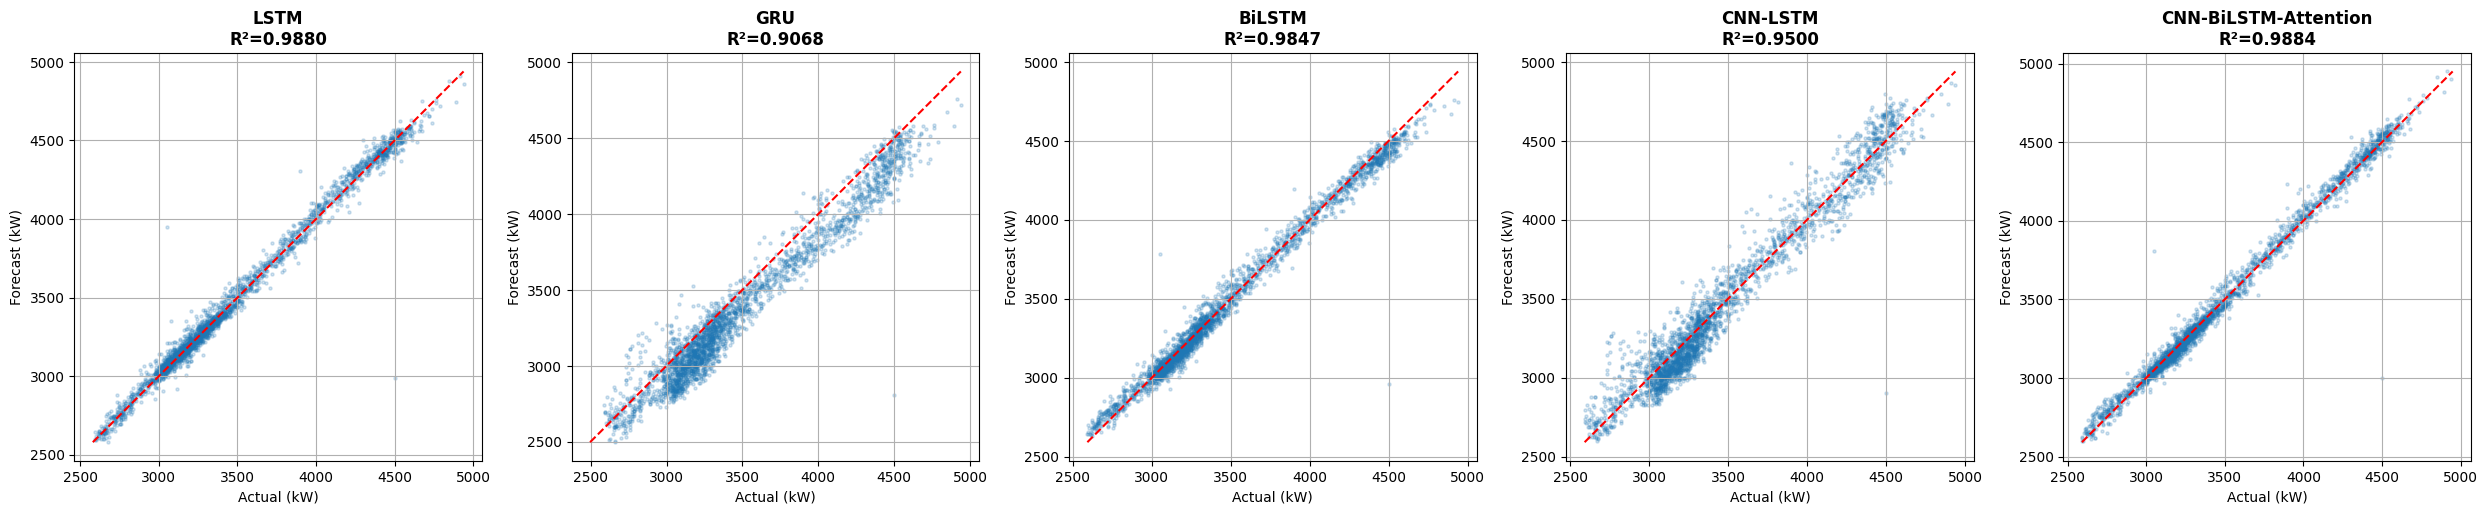

In [7]:
# 2.5 Scatter plots
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_true_real, y_pred, alpha=0.2, s=5)
    lims = [min(y_true_real.min(), y_pred.min()), max(y_true_real.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5)
    ax.set_title(f'{name}\nR²={all_metrics[name]["R2"]:.4f}', fontweight='bold')
    ax.set_xlabel('Actual (kW)')
    ax.set_ylabel('Forecast (kW)')
    ax.set_aspect('equal')
    ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'comparison_scatter.png'), dpi=150)
plt.show()

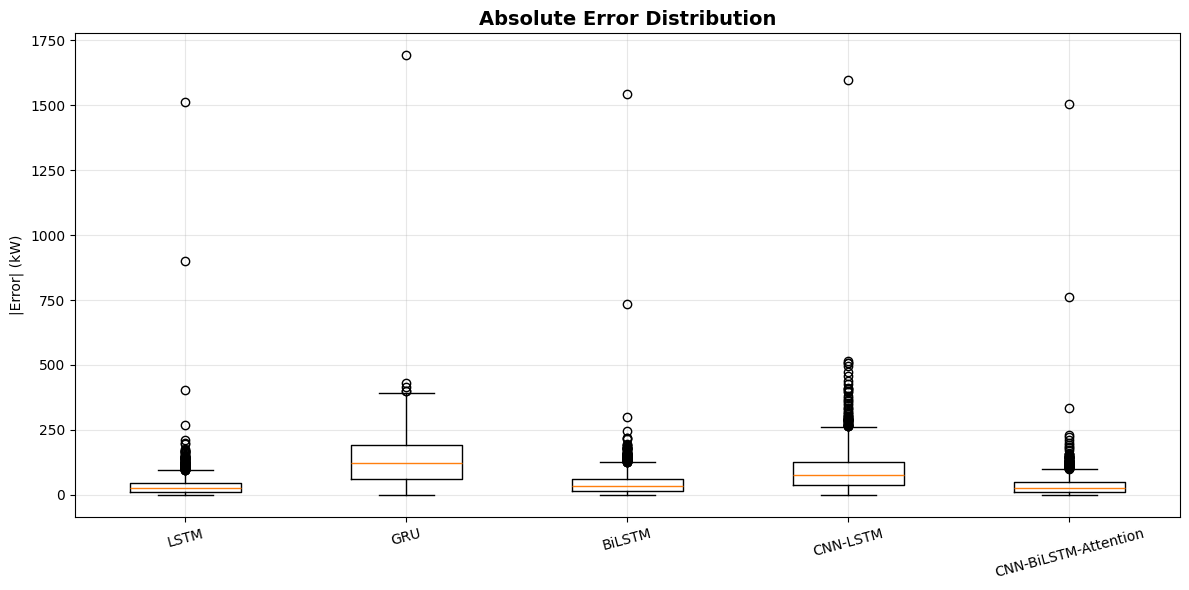


Notebook 05 hoàn tất! Tiếp theo: 06_Microgrid_Optimization.ipynb


In [ ]:
# 2.6 Box plot of errors
errors = {name: np.abs(y_true_real - y_pred) for name, y_pred in predictions.items()}

fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot(errors.values(), labels=errors.keys())
ax.set_title('Absolute Error Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('|Error| (kW)')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'comparison_boxplot.png'), dpi=150)
plt.show()


print('\nNotebook 05 completed! Next: 06_Microgrid_Optimization.ipynb')